In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Libraries and packages

In [5]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve

# **DATA**  **lOADING**

In [6]:
df = pd.read_csv("/content/drive/MyDrive/ict/loan.csv")

In [7]:
# Displaying first 5 data

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


#  **To** **check** **the** **missing** **value** **of** **each** **column**

In [8]:
df.isna().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [9]:
# Datatypes
df.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [10]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [11]:
from sklearn.impute import KNNImputer

In [12]:
km =  KNNImputer(n_neighbors=5)

In [13]:
df_numerical = df.select_dtypes(exclude=["object"])


In [14]:
imdata = km.fit_transform(df_numerical)

In [15]:
imdata

array([[5.849e+03, 0.000e+00, 1.478e+02, 3.600e+02, 1.000e+00],
       [4.583e+03, 1.508e+03, 1.280e+02, 3.600e+02, 1.000e+00],
       [3.000e+03, 0.000e+00, 6.600e+01, 3.600e+02, 1.000e+00],
       ...,
       [8.072e+03, 2.400e+02, 2.530e+02, 3.600e+02, 1.000e+00],
       [7.583e+03, 0.000e+00, 1.870e+02, 3.600e+02, 1.000e+00],
       [4.583e+03, 0.000e+00, 1.330e+02, 3.600e+02, 0.000e+00]])

In [16]:

df_imdata = pd.DataFrame(data=imdata , columns=df_numerical.columns)

In [17]:
df_imdata.head(2)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849.0,0.0,147.8,360.0,1.0
1,4583.0,1508.0,128.0,360.0,1.0


In [18]:
df_imdata.isna().sum()

,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [19]:
from sklearn.impute import SimpleImputer  # we use this for catagorical value

In [20]:
df_categories = df.select_dtypes(include=["object"])

In [21]:
sm =  SimpleImputer(strategy="most_frequent")

In [22]:

smdata = sm.fit_transform(df_categories)

In [23]:
smdata

array([['LP001002', 'Male', 'No', ..., 'No', 'Urban', 'Y'],
       ['LP001003', 'Male', 'Yes', ..., 'No', 'Rural', 'N'],
       ['LP001005', 'Male', 'Yes', ..., 'Yes', 'Urban', 'Y'],
       ...,
       ['LP002983', 'Male', 'Yes', ..., 'No', 'Urban', 'Y'],
       ['LP002984', 'Male', 'Yes', ..., 'No', 'Urban', 'Y'],
       ['LP002990', 'Female', 'No', ..., 'Yes', 'Semiurban', 'N']],
      dtype=object)

In [24]:
df_smdata = pd.DataFrame(data=imdata , columns=df_numerical.columns)

In [25]:
df_smdata.isna().sum()

,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [26]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [27]:
target_data = df["Loan_Status"]


# Extracting target data's name
target = target_data.name

# **FUTURE** **ENCODING**

In [29]:
# Handling encodings
df.drop(columns=["Loan_ID"], inplace=True)

df_categories = df.select_dtypes(include=["object"])

cat_cols = df_categories.columns



for col in cat_cols:
  print(f"{col} : {df[col].unique()}")

Gender : ['Male' 'Female' nan]
Married : ['No' 'Yes' nan]
Dependents : ['0' '1' '2' '3+' nan]
Education : ['Graduate' 'Not Graduate']
Self_Employed : ['No' 'Yes' nan]
Property_Area : ['Urban' 'Rural' 'Semiurban']
Loan_Status : ['Y' 'N']


In [30]:
oh_encoding_cols = ['Gender',
 'Married',
 'Dependents',
 'Self_Employed',
 'Property_Area',
]

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(df[oh_encoding_cols])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(oh_encoding_cols),
    index=df.index
)

# Remove the original categorical columns
df = df.drop(columns=oh_encoding_cols)

# Combine encoded and numerical columns
df = pd.concat([df, encoded_df], axis=1)

In [31]:
lb_encoding_cols = [col for col in df_categories.columns if col not in oh_encoding_cols]
lb_encoding_cols

['Education', 'Loan_Status']

In [32]:
le = LabelEncoder()

for col in lb_encoding_cols:
  df[col] = le.fit_transform(df[col].astype(str))

In [33]:
df.head()

,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Gender_nan,Married_Yes,Married_nan,Dependents_1,Dependents_2,Dependents_3+,Dependents_nan,Self_Employed_Yes,Self_Employed_nan,Property_Area_Semiurban,Property_Area_Urban
0,0,5849,0.0,NaN,360.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0,4583,1508.0,128.0,360.0,1.0,0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,3000,0.0,66.0,360.0,1.0,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1,2583,2358.0,120.0,360.0,1.0,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0,6000,0.0,141.0,360.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [34]:
todrop=["Gender_Male","Gender_nan","Married_Yes","Married_nan"]
df.drop(columns=todrop,inplace=True)

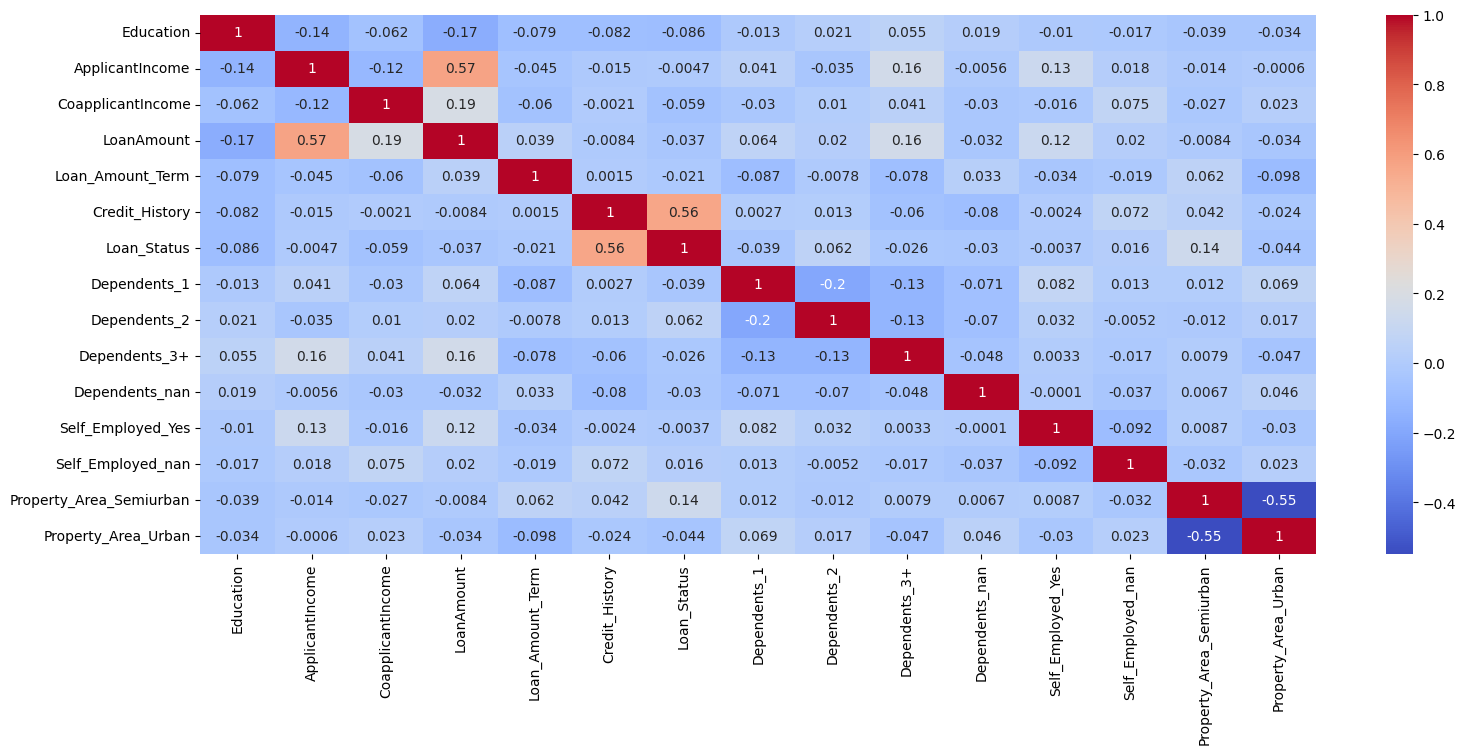

In [35]:
plt.figure(figsize=(18,7))
result=df.corr()
sns.heatmap(data=result,cmap="coolwarm",annot=True)
plt.show()

# **OUTLIER** **TREATMENT**

In [36]:
columns_selected=["LoanAmount","Loan_Amount_Term","Dependents_1","Dependents_3+",
                  "Dependents_nan","Self_Employed_Yes","Self_Employed_nan","Property_Area_Semiurban"]
df.drop(columns=columns_selected,inplace=True)

In [37]:
df.head()

,Education,ApplicantIncome,CoapplicantIncome,Credit_History,Loan_Status,Dependents_2,Property_Area_Urban
0,0,5849,0.0,1.0,1,0.0,1.0
1,0,4583,1508.0,1.0,0,0.0,0.0
2,0,3000,0.0,1.0,1,0.0,1.0
3,1,2583,2358.0,1.0,1,0.0,1.0
4,0,6000,0.0,1.0,1,0.0,1.0


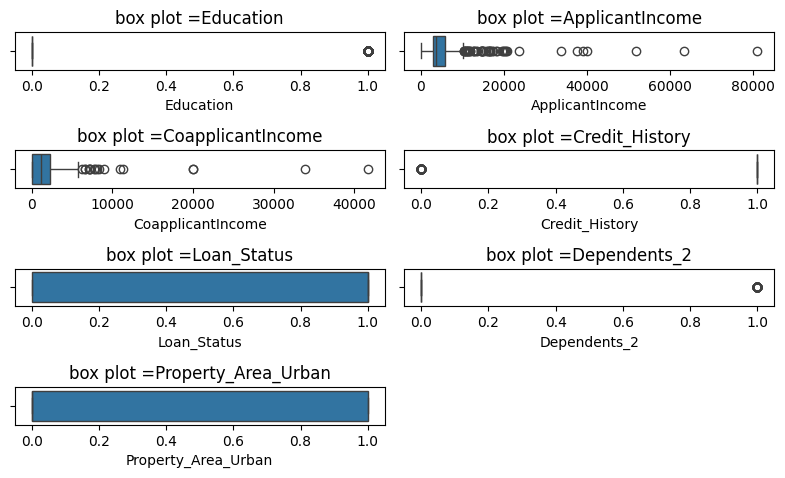

In [38]:
columns=df.columns
plt.figure(figsize=(8,8))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

In [39]:
df["ApplicantIncome"].describe()

,ApplicantIncome
count,614.000000
mean,5403.459283
std,6109.041673
min,150.000000
25%,2877.500000
50%,3812.500000
75%,5795.000000
max,81000.000000


In [56]:
columns = ['ApplicantIncome', 'CoapplicantIncome','Education', 'ApplicantIncome','Credit_History','Dependents_2']

for col in columns:
#find  first and third quantile
  q1=df[col].quantile(0.25)
  q3=df[col].quantile(0.75)
#find the iqr
  iqr=q3-q1
for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Replace outliers with upper and lower boundary limits
    df[col] = df[col].clip(lower=lower, upper=upper)


In [57]:
outlier[col]

,Dependents_2


In [58]:
df[col]=df[col].clip(upper=upper,lower=lower)# to replace the value of outiler with the

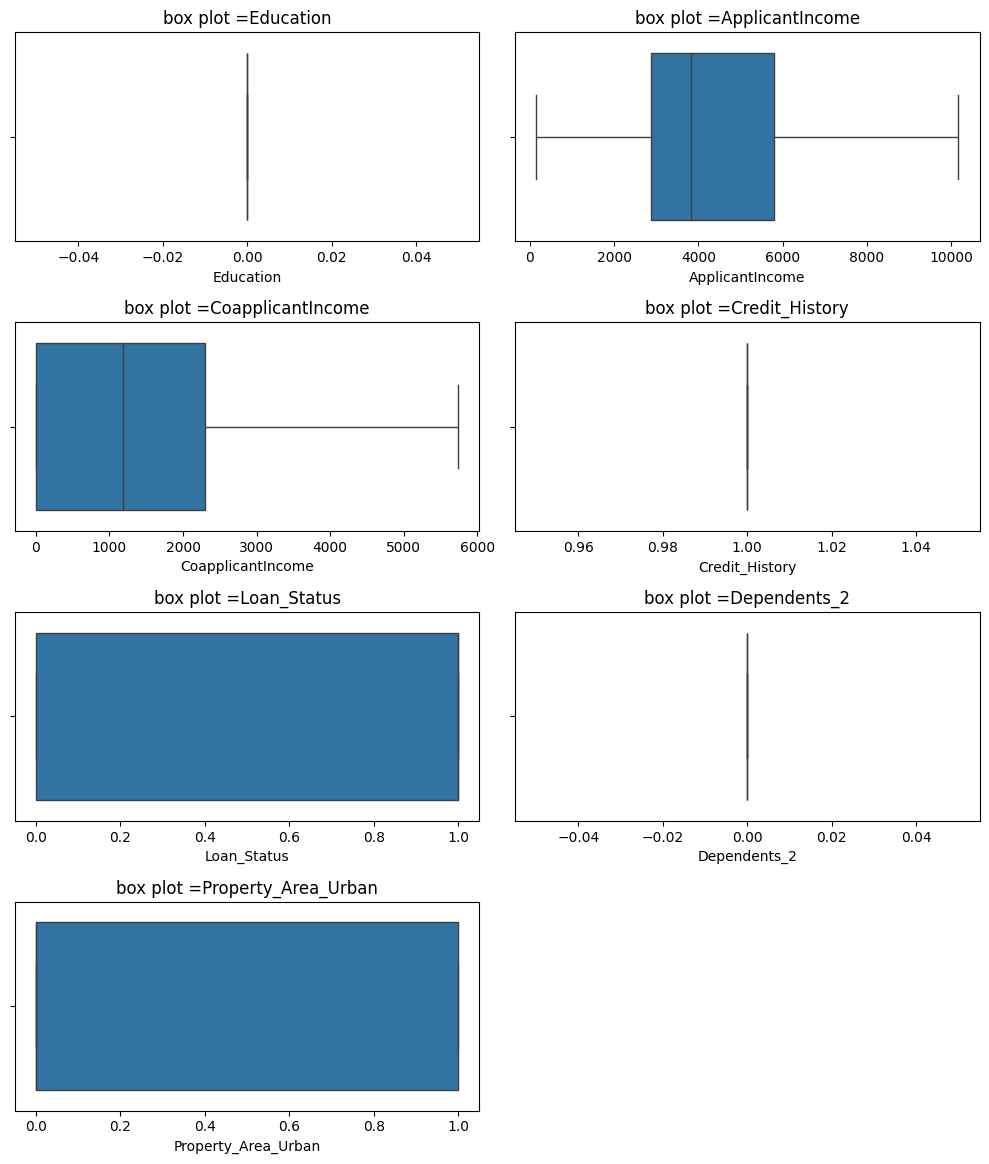

In [59]:
columns=df.columns
plt.figure(figsize=(10,20))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

there is no outliers in this code

In [60]:
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

In [61]:
X_train, X_test , y_train , y_test=train_test_split(X,y,train_size=0.8,random_state=42)

#Feature Engineering and Target Seperation

In [62]:
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

In [64]:
X = df.drop(["Loan_Status"], axis=1)

y = df["Loan_Status"]

# Convert remaining categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (614, 7)
y shape: (614,)


In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (491, 7)
X_test shape: (123, 7)
y_train shape: (491,)
y_test shape: (123,)


In [66]:
print(y_train.value_counts())

Loan_Status
1    337
0    154
Name: count, dtype: int64


In [67]:
print(y_train.value_counts(normalize=True) * 100)

Loan_Status
1    68.635438
0    31.364562
Name: proportion, dtype: float64


In [68]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [69]:
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)

X_test = imputer.transform(X_test)

print("Missing values handled")

Missing values handled


#Feature Scaling

In [70]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


##SMOTE

In [71]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Loan_Status
1    337
0    154
Name: count, dtype: int64

After SMOTE:
Loan_Status
1    337
0    337
Name: count, dtype: int64


## MODEL SELECTION

In [105]:
from sklearn.svm import SVC

In [106]:
lr = LogisticRegression(max_iter=1000)
svm = SVC()

## Model training

In [107]:
svm.fit(X_train_smote, y_train_smote)
lr.fit(X_train_smote, y_train_smote)

LogisticRegression(max_iter=1000)

In [120]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


## MODEL evaluations

### logistic

In [121]:
y_predl = lr.predict(X_test_scaled)
y_predl

array([0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0])

In [122]:
mean_sq_l= mean_squared_error(y_test,y_predl)
mean_ab_l = mean_absolute_error(y_test,y_predl)
r2_l = r2_score(y_test,y_predl)
print(mean_sq_l,mean_ab_l,r2_l)

0.44715447154471544 0.44715447154471544 -1.094427244582043


### SVM

In [123]:
y_predsvm = svm.predict(X_test_scaled)
y_predsvm

array([0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

In [124]:
mean_sq_svm= mean_squared_error(y_test,y_predsvm)
mean_ab_svm = mean_absolute_error(y_test,y_predsvm)
r2_svm = r2_score(y_test,y_predsvm)
print(mean_sq_svm,mean_ab_svm,r2_svm)

0.5609756097560976 0.5609756097560976 -1.627554179566563


### result

In [125]:
# Create a comparison DataFrame

results_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM'],
    'Accuracy': [accuracy_score(y_test, y_predl), accuracy_score(y_test, y_predsvm)],
    'ROC-AUC': [roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]), 'N/A']
})
# Find and print the best model (highest R2 Score)
best_model = results_df.loc[results_df['Accuracy'].idxmax()]
print("\n--- Best Model ---")
print(f"Model Name: {best_model['Model']}")
print(f"Highest Accuracy: {best_model['Accuracy']:.4f}")


--- Best Model ---
Model Name: Logistic Regression
Highest Accuracy: 0.5528


# best model is logictic regresion

# Classification

## import models

In [150]:
from sklearn.ensemble import RandomForestClassifier

In [151]:
rc = RandomForestClassifier(random_state=42)

## model training

In [152]:
rc.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

## Model evaluations

In [157]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix

### random class

In [158]:
y_pred_rc = rc.predict(X_test_scaled)

In [159]:
accuracy_rc = accuracy_score(y_test, y_pred_rc)
precision_rc = precision_score(y_test, y_pred_rc)
recall_rc = recall_score(y_test, y_pred_rc)
f1_rc = f1_score(y_test, y_pred_rc)

print("Accuracy :", accuracy_rc)
print("Precision:", precision_rc)
print("Recall   :", recall_rc)
print("F1 Score :", f1_rc)

Accuracy : 0.3089430894308943
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### result

In [167]:


# 2. Create the comparison DataFrame
results_df = pd.DataFrame({
    'Model': ['Logistic Regression (Base)', 'Random Forest (Ensemble)'],
    'Accuracy': [accuracy_score(y_test, y_predl), accuracy_score(y_test, y_pred_rc)],
    'Precision': [
        precision_score(y_test, y_predl, zero_division=0),
        precision_score(y_test, y_pred_rc, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_predl, zero_division=0),
        recall_score(y_test, y_pred_rc, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_predl, zero_division=0),
        f1_score(y_test, y_pred_rc, zero_division=0)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, lr.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, rc.predict_proba(X_test_scaled)[:, 1])
    ]
})

print(results_df)

# 3. Find and print the best model based on Accuracy
best_model = results_df.loc[results_df['Accuracy'].idxmax()]
print("\n--- Best Model ---")
print(f"Model Name: {best_model['Model']}")
print(f"Accuracy: {best_model['Accuracy']:.4f}")

                        Model  Accuracy  Precision  Recall  F1 Score   ROC-AUC
0  Logistic Regression (Base)  0.552846   0.708333     0.6  0.649682  0.472910
1    Random Forest (Ensemble)  0.308943   0.000000     0.0  0.000000  0.512229

--- Best Model ---
Model Name: Logistic Regression (Base)
Accuracy: 0.5528


In [168]:
accuracy = accuracy_score(y_test, y_predl)
precision = precision_score(y_test, y_predl)
recall = recall_score(y_test, y_predl)
f1 = f1_score(y_test, y_predl)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.5528455284552846
Precision: 0.7083333333333334
Recall   : 0.6
F1 Score : 0.6496815286624203


In [169]:
cm = confusion_matrix(y_test, y_predl)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[17 21]
 [34 51]]


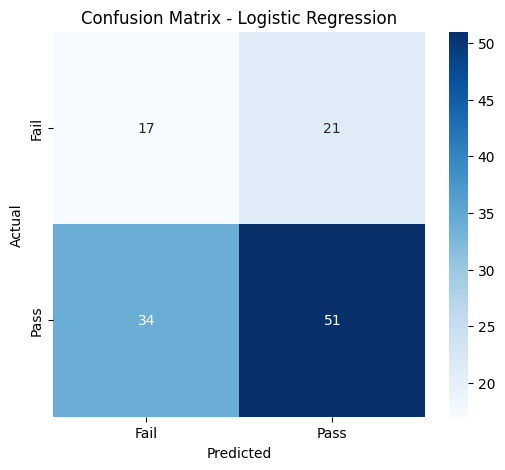

In [170]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

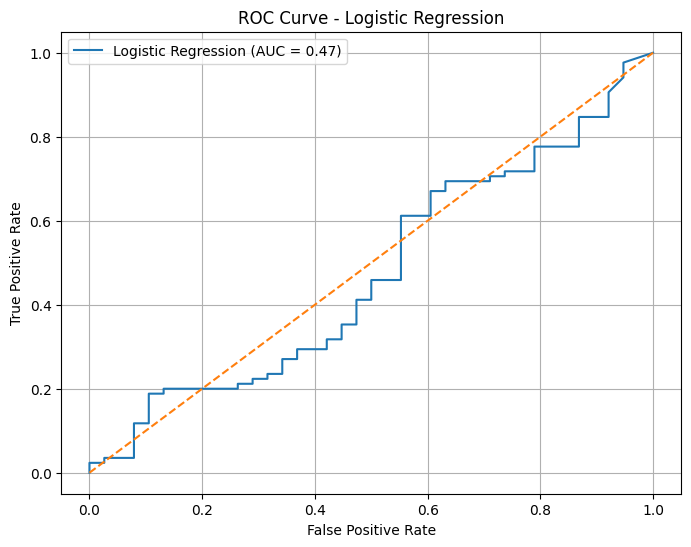

AUC: 0.4729102167182663


In [171]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predicted probability for the positive class (Pass)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC
auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

print("AUC:", auc)

# **Hyperparameter Tuning**

In [172]:
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA


In [173]:
param_grid = {
    "fit_intercept" : [True, False]
}

lr_grid = GridSearchCV(estimator = lr,
                       param_grid = param_grid,
                       n_jobs = 1,
                       scoring = "accuracy",
                       cv = 5)
lr_grid.fit(X_train_scaled,y_train)


# 1. Use best_estimator_ (not estimator)
lr_best_model = lr_grid.best_estimator_

print(f"Best Parameter with Values : {lr_grid.best_params_}, Score : {lr_grid.best_score_}")

Best Parameter with Values : {'fit_intercept': True}, Score : 0.686353329210472


In [174]:
# pca
pca = PCA(n_components=2)

X_reduced = pca.fit_transform(X_train_scaled)

print("before reduction",X_train_scaled.shape)
print("after reduction",X_reduced.shape)


print(pca.explained_variance_ratio_.sum())

before reduction (491, 7)
after reduction (491, 2)
0.7542686238801558


# **Model Saving**

In [175]:
import joblib

In [176]:
with open("logistic_regression_model.pkl","wb")as file:
  joblib.dump(lr_best_model,file)
with open("logistic_regression_model.pkl","rb")as file:
  model = joblib.load(file)

print("Model saved and loaded successfully!")

Model saved and loaded successfully!


# **Model Testing**

In [177]:
y_test.head() # if we use xbg booster scaler is not mandratory

,Loan_Status
150,0
559,1
598,1
235,1
145,1


In [179]:
# Create a sample with all 7 features (matching your model's expected shape)
new_data = [[0, 5849.0, 0.0, 1.0, 0.0, 0.0, 1.0]]

# Scale the data using your already fitted scaler
new_data_scaled = scaler.transform(new_data)

# Make the prediction
result = model.predict(new_data_scaled)
probability = model.predict_proba(new_data_scaled)

print("Prediction (0 = Rejected, 1 = Approved):", result[0])
print("Probability:", probability[0])

Prediction (0 = Rejected, 1 = Approved): 1
Probability: [0.292699 0.707301]
